In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [24]:
# Cấu hình style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)

# Đường dẫn file CSV (Sửa lại nếu đường dẫn của bạn khác)
CSV_PATH = "../../outputs_evaluation/aggregated_k_shot_detailed.csv"

# Đọc dữ liệu
df = pd.read_csv(CSV_PATH)

print("✅ Đã load dữ liệu thành công!")

✅ Đã load dữ liệu thành công!


In [35]:
# Chuyển đổi cột Shots
df['Shots_Int'] = df['Shots'].str.extract(r'(\d+)').astype(int)

# Lọc 2 phương pháp và 2 protocol chính
methods = ['tstcc', 'tstcc_swav']
protocols = ['full_finetuning', 'linear_probing']

df_compare = df[df['Method'].isin(methods) & df['Protocol'].isin(protocols)].copy()

# Tạo cột tên cặp
df_compare['Pair'] = df_compare['Source'] + " ➔ " + df_compare['Target']

# Tính trung bình F1 trên toàn bộ 12 cặp (hoặc ít hơn nếu có cặp thiếu)
df_grouped = df_compare.groupby(['Method', 'Protocol', 'Shots_Int']).agg(
    F1_Mean=('F1_Mean', 'mean'),
    F1_Std=('F1_Std', 'mean')
).reset_index()

print(f"✅ Đã load dữ liệu. Tổng số dòng: {len(df_compare)}")

✅ Đã load dữ liệu. Tổng số dòng: 242


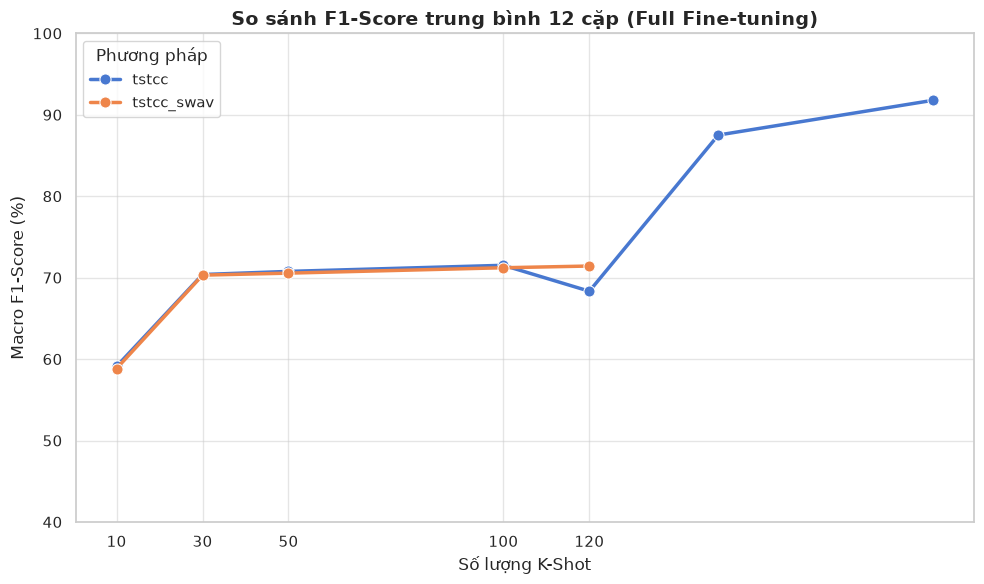

In [36]:
plt.figure(figsize=(10, 6))
df_plot_full = df_grouped[df_grouped['Protocol'] == 'full_finetuning']

sns.lineplot(
    data=df_plot_full, x='Shots_Int', y='F1_Mean', hue='Method',
    marker='o', linewidth=2.5, markersize=8
)

plt.title('So sánh F1-Score trung bình 12 cặp (Full Fine-tuning)', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng K-Shot', fontsize=12)
plt.ylabel('Macro F1-Score (%)', fontsize=12)
plt.xticks([10, 30, 50, 100, 120])
plt.ylim(40, 100)
plt.legend(title='Phương pháp')
plt.tight_layout()
plt.show()

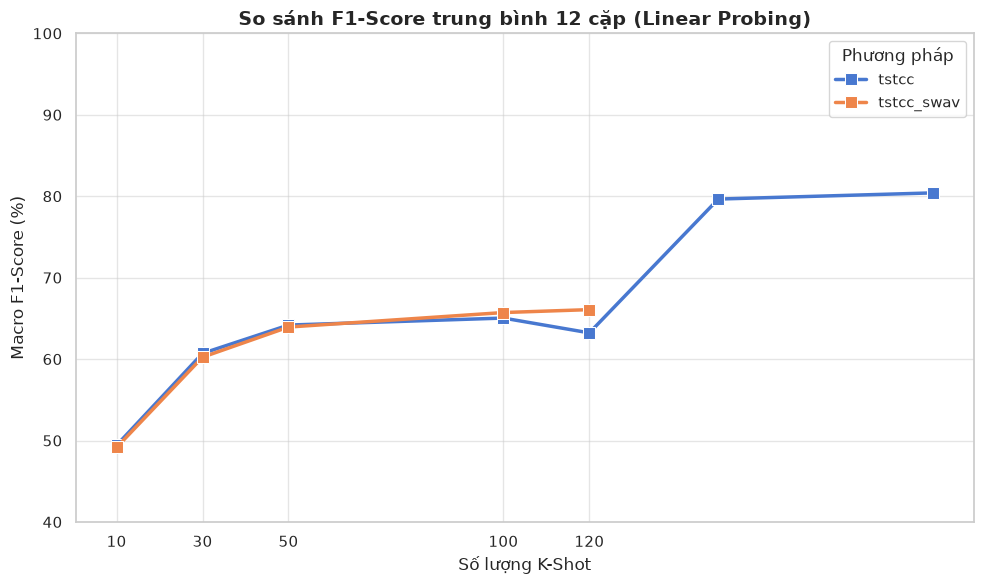

In [37]:
plt.figure(figsize=(10, 6))
df_plot_linear = df_grouped[df_grouped['Protocol'] == 'linear_probing']

sns.lineplot(
    data=df_plot_linear, x='Shots_Int', y='F1_Mean', hue='Method',
    marker='s', linewidth=2.5, markersize=8
)

plt.title('So sánh F1-Score trung bình 12 cặp (Linear Probing)', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng K-Shot', fontsize=12)
plt.ylabel('Macro F1-Score (%)', fontsize=12)
plt.xticks([10, 30, 50, 100, 120])
plt.ylim(40, 100)
plt.legend(title='Phương pháp')
plt.tight_layout()
plt.show()

In [38]:
# Lấy dữ liệu Full Fine-tuning
df_detail = df_compare[df_compare['Protocol'] == 'full_finetuning']

# Tạo bảng Pivot: hàng là cặp, cột là (Method, Shots)
pivot_detail = df_detail.pivot_table(
    index='Pair',
    columns=['Method', 'Shots_Int'],
    values='F1_Mean'
)

# Sắp xếp lại cột cho đẹp (TSTCC trước, SwAV sau)
pivot_detail = pivot_detail.sort_index(axis=1, level=0)

print("BẢNG ĐIỂM CHI TIẾT 12 CẶP (Full Fine-tuning):")
display(pivot_detail.round(2))

BẢNG ĐIỂM CHI TIẾT 12 CẶP (Full Fine-tuning):


Method                     tstcc                                            \
Shots_Int                    10     30     50     100    120    150    200   
Pair                                                                         
hhar_phone ➔ hhar_watch    36.56  42.44  40.22  37.36  36.00    NaN    NaN   
hhar_phone ➔ motion_sense  68.19  82.25  81.09  83.93  83.30    NaN    NaN   
hhar_phone ➔ uci_har       73.76  88.24  90.17  91.90  92.35    NaN    NaN   
hhar_watch ➔ hhar_phone    63.46  73.06  73.51  76.47  76.47    NaN    NaN   
hhar_watch ➔ motion_sense  74.38  80.51  80.15  83.01  81.79    NaN    NaN   
hhar_watch ➔ uci_har       74.19  87.03  88.41  90.43  90.91    NaN    NaN   
motion_sense ➔ hhar_phone  58.83  72.70  74.14  75.09  77.46    NaN    NaN   
motion_sense ➔ hhar_watch  24.64  38.55  37.31  35.15  33.85    NaN    NaN   
motion_sense ➔ uci_har     70.55  88.28  89.99  91.73    NaN  92.75  91.78   
uci_har ➔ hhar_phone       56.11  68.85  69.74  73.34  75.32    NaN    NaN   
uci_har ➔ hhar_watch       34.56  41.69  42.57  37.18  35.89    NaN    NaN   
uci_har ➔ motion_sense     74.04  80.99  81.92  82.62    NaN  82.27    NaN   

Method                    tstcc_swav                              
Shots_Int                        10     30     50     100    120  
Pair                                                              
hhar_phone ➔ hhar_watch        45.77  48.54  40.55  36.45  36.26  
hhar_phone ➔ motion_sense      62.88  77.03  79.79  81.11  81.31  
hhar_phone ➔ uci_har           73.49  88.73  90.19  91.81  91.78  
hhar_watch ➔ hhar_phone        59.43  70.40  70.70  73.88  74.31  
hhar_watch ➔ motion_sense      73.88  82.26  83.85  86.85  88.32  
hhar_watch ➔ uci_har           73.76  89.06  90.42  92.14  92.44  
motion_sense ➔ hhar_phone      52.48  68.09  69.35  71.39  73.25  
motion_sense ➔ hhar_watch      25.74  42.02  44.54  40.25  36.90  
motion_sense ➔ uci_har         71.12  87.28  89.11  90.89  91.60  
uci_har ➔ hhar_phone           56.97  68.35  68.45  70.49  73.64  
uci_har ➔ hhar_watch           34.64  40.64  39.78  38.36  35.74  
uci_har ➔ motion_sense         75.97  81.29  79.91  80.98  81.57

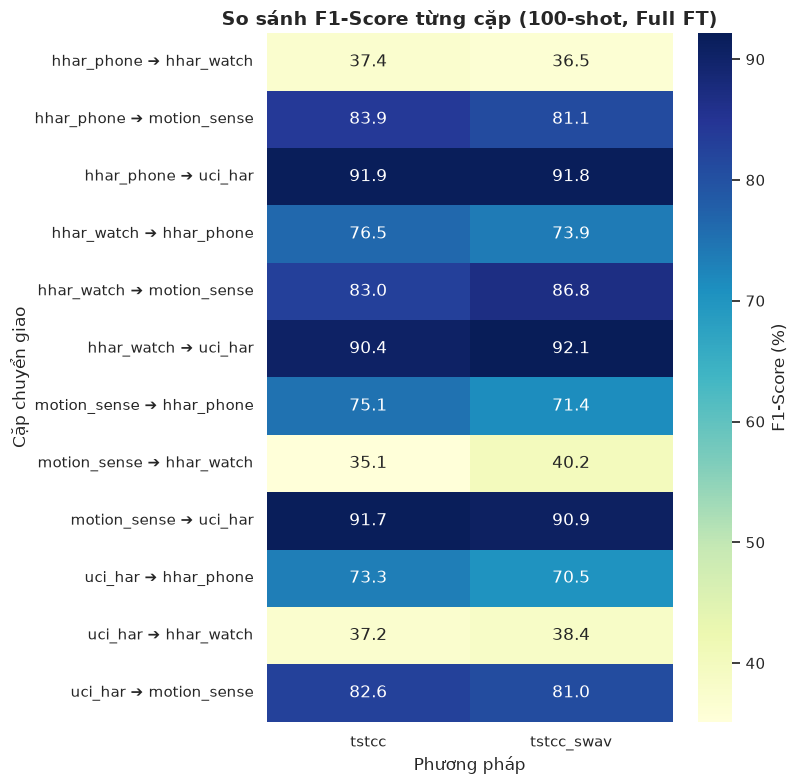

In [40]:
# Lấy dữ liệu 100-shot, Full Fine-tuning
df_heatmap = df_compare[
    (df_compare['Protocol'] == 'full_finetuning') &
    (df_compare['Shots_Int'] == 100)
]

# Pivot: Hàng là cặp, Cột là Phương pháp
heatmap_data = df_heatmap.pivot(index='Pair', columns='Method', values='F1_Mean')

plt.figure(figsize=(8, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'F1-Score (%)'})
plt.title('So sánh F1-Score từng cặp (100-shot, Full FT)', fontsize=14, fontweight='bold')
plt.ylabel('Cặp chuyển giao')
plt.xlabel('Phương pháp')
plt.tight_layout()
plt.show()

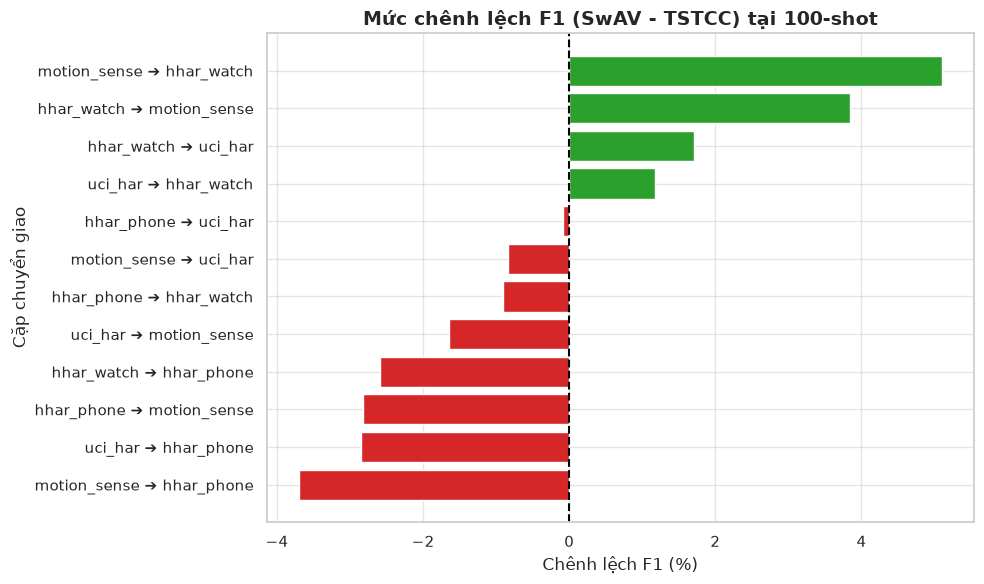

In [41]:
# Tính chênh lệch
heatmap_data['Difference'] = heatmap_data['tstcc_swav'] - heatmap_data['tstcc']
diff_series = heatmap_data['Difference'].sort_values()

plt.figure(figsize=(10, 6))
colors = ['#d62728' if val < 0 else '#2ca02c' for val in diff_series.values] # Đỏ: TSTCC tốt hơn, Xanh: SwAV tốt hơn

plt.barh(diff_series.index, diff_series.values, color=colors)
plt.axvline(0, color='black', linestyle='--')
plt.title('Mức chênh lệch F1 (SwAV - TSTCC) tại 100-shot', fontsize=14, fontweight='bold')
plt.xlabel('Chênh lệch F1 (%)')
plt.ylabel('Cặp chuyển giao')
plt.tight_layout()
plt.show()

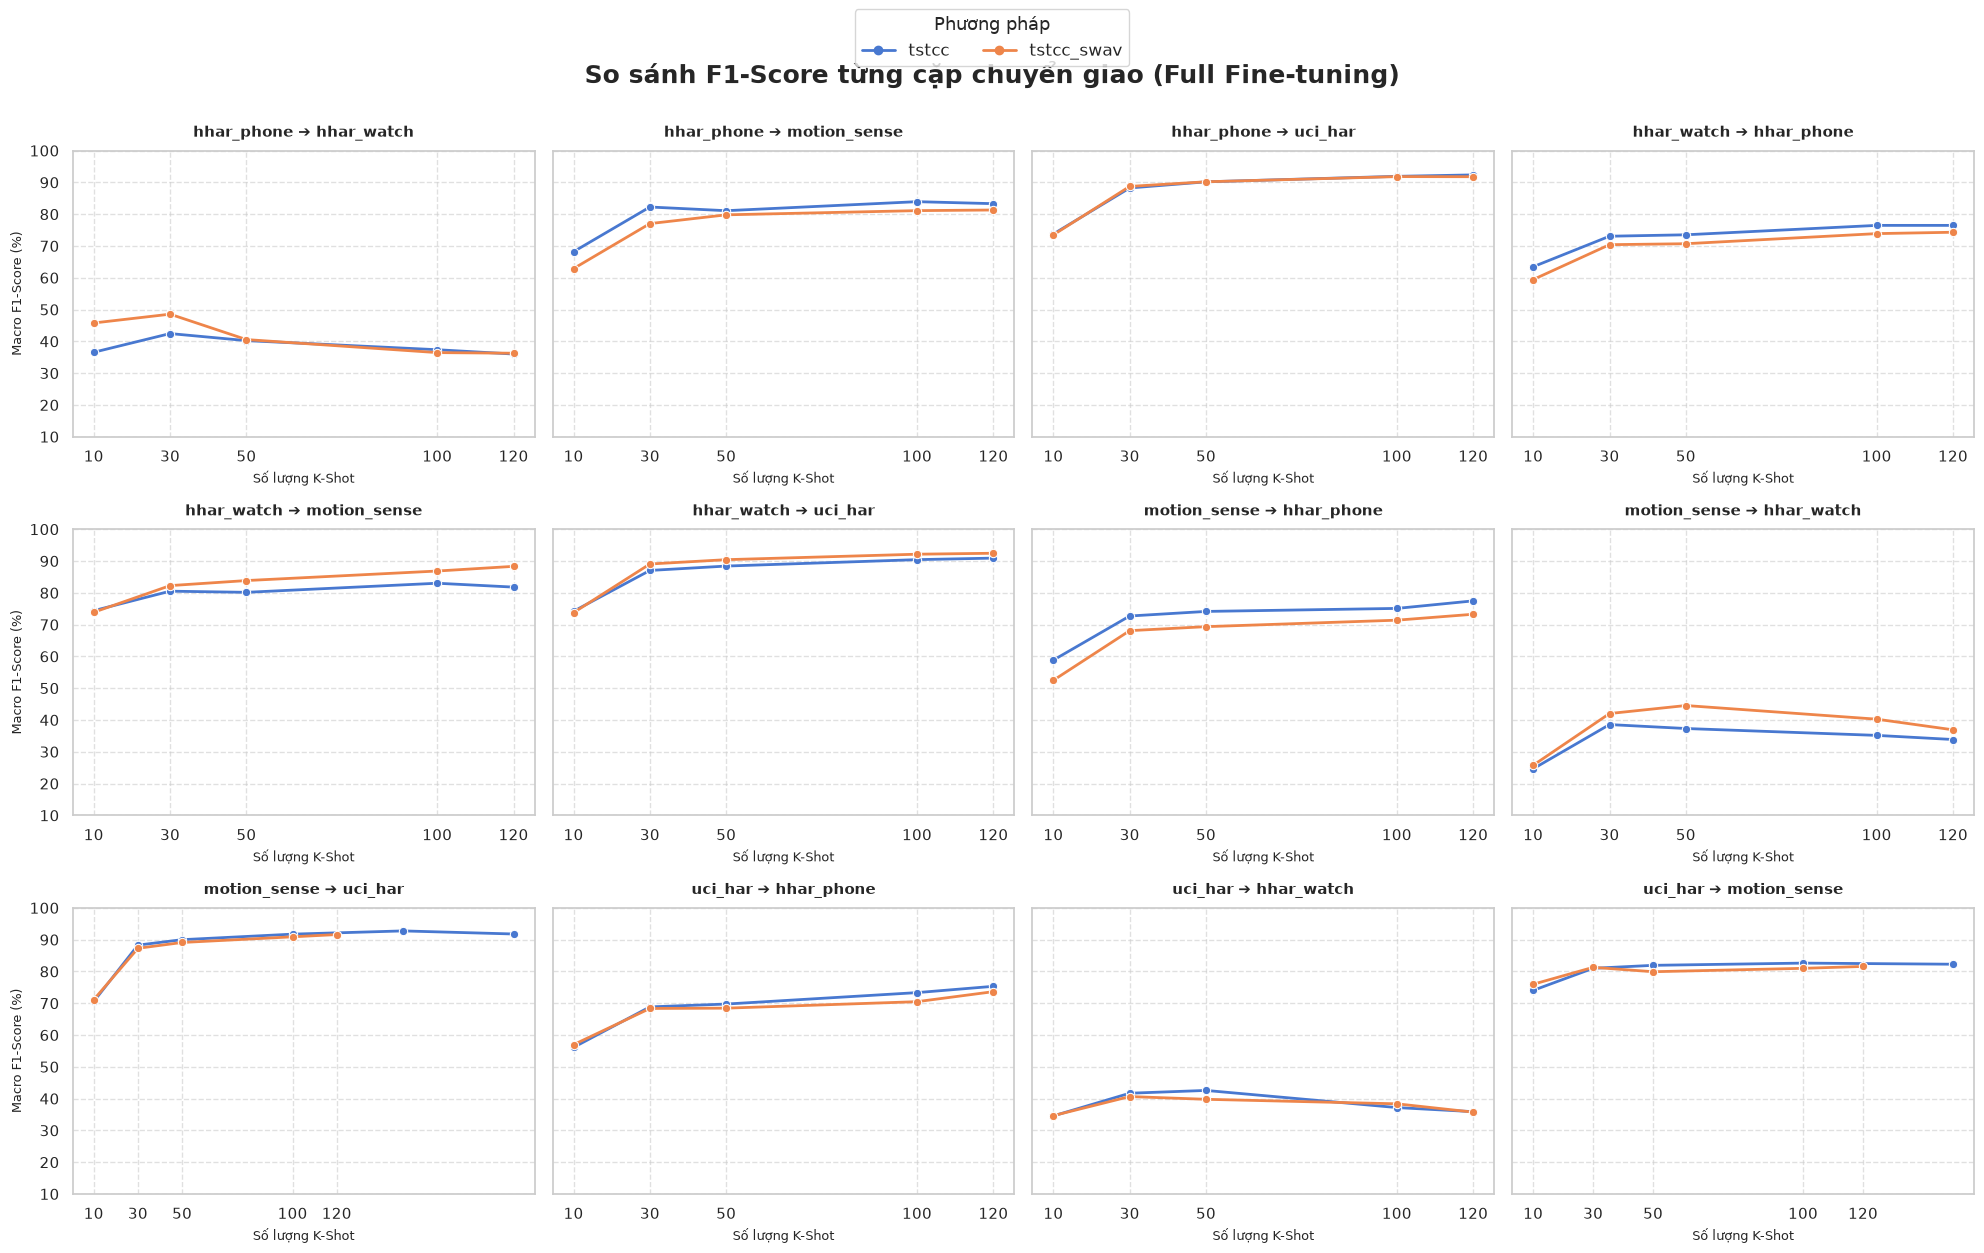

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Lấy dữ liệu Full Fine-tuning
df_full = df_compare[df_compare['Protocol'] == 'full_finetuning'].copy()

# Lấy danh sách 12 cặp và sắp xếp
unique_pairs = sorted(df_full['Pair'].unique())

# Tạo lưới biểu đồ
fig, axes = plt.subplots(3, 4, figsize=(20, 12), sharey=True)
axes = axes.flatten()

for i, pair in enumerate(unique_pairs):
    ax = axes[i]
    df_pair = df_full[df_full['Pair'] == pair]

    # Vẽ đường, bỏ legend tự động của seaborn (legend=False)
    sns.lineplot(
        data=df_pair, x='Shots_Int', y='F1_Mean', hue='Method',
        marker='o', linewidth=2, markersize=6, ax=ax, legend=False
    )

    ax.set_title(f'{pair}', fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel('Số lượng K-Shot', fontsize=9)
    ax.set_ylabel('Macro F1-Score (%)', fontsize=9)
    ax.set_xticks([10, 30, 50, 100, 120])
    ax.set_ylim(10, 100)
    ax.grid(True, linestyle='--', alpha=0.6)

# Tạo Legend chung ở phía trên
# Tự tạo các đường kẻ mẫu cho legend
custom_lines = [
    Line2D([0], [0], color=sns.color_palette("muted")[0], lw=2, marker='o'),
    Line2D([0], [0], color=sns.color_palette("muted")[1], lw=2, marker='o')
]

# Đặt legend chung ở giữa, phía trên
fig.legend(
    custom_lines,
    ['tstcc', 'tstcc_swav'],
    title='Phương pháp',
    loc='upper center',
    bbox_to_anchor=(0.5, 1.05), # Đẩy legend lên trên tiêu đề một chút
    ncol=2,
    fontsize=12,
    title_fontsize=13
)

# Tiêu đề chung (đặt thấp hơn legend một chút)
plt.suptitle('So sánh F1-Score từng cặp chuyển giao (Full Fine-tuning)', fontsize=18, fontweight='bold', y=1.0)

plt.tight_layout()
plt.show()

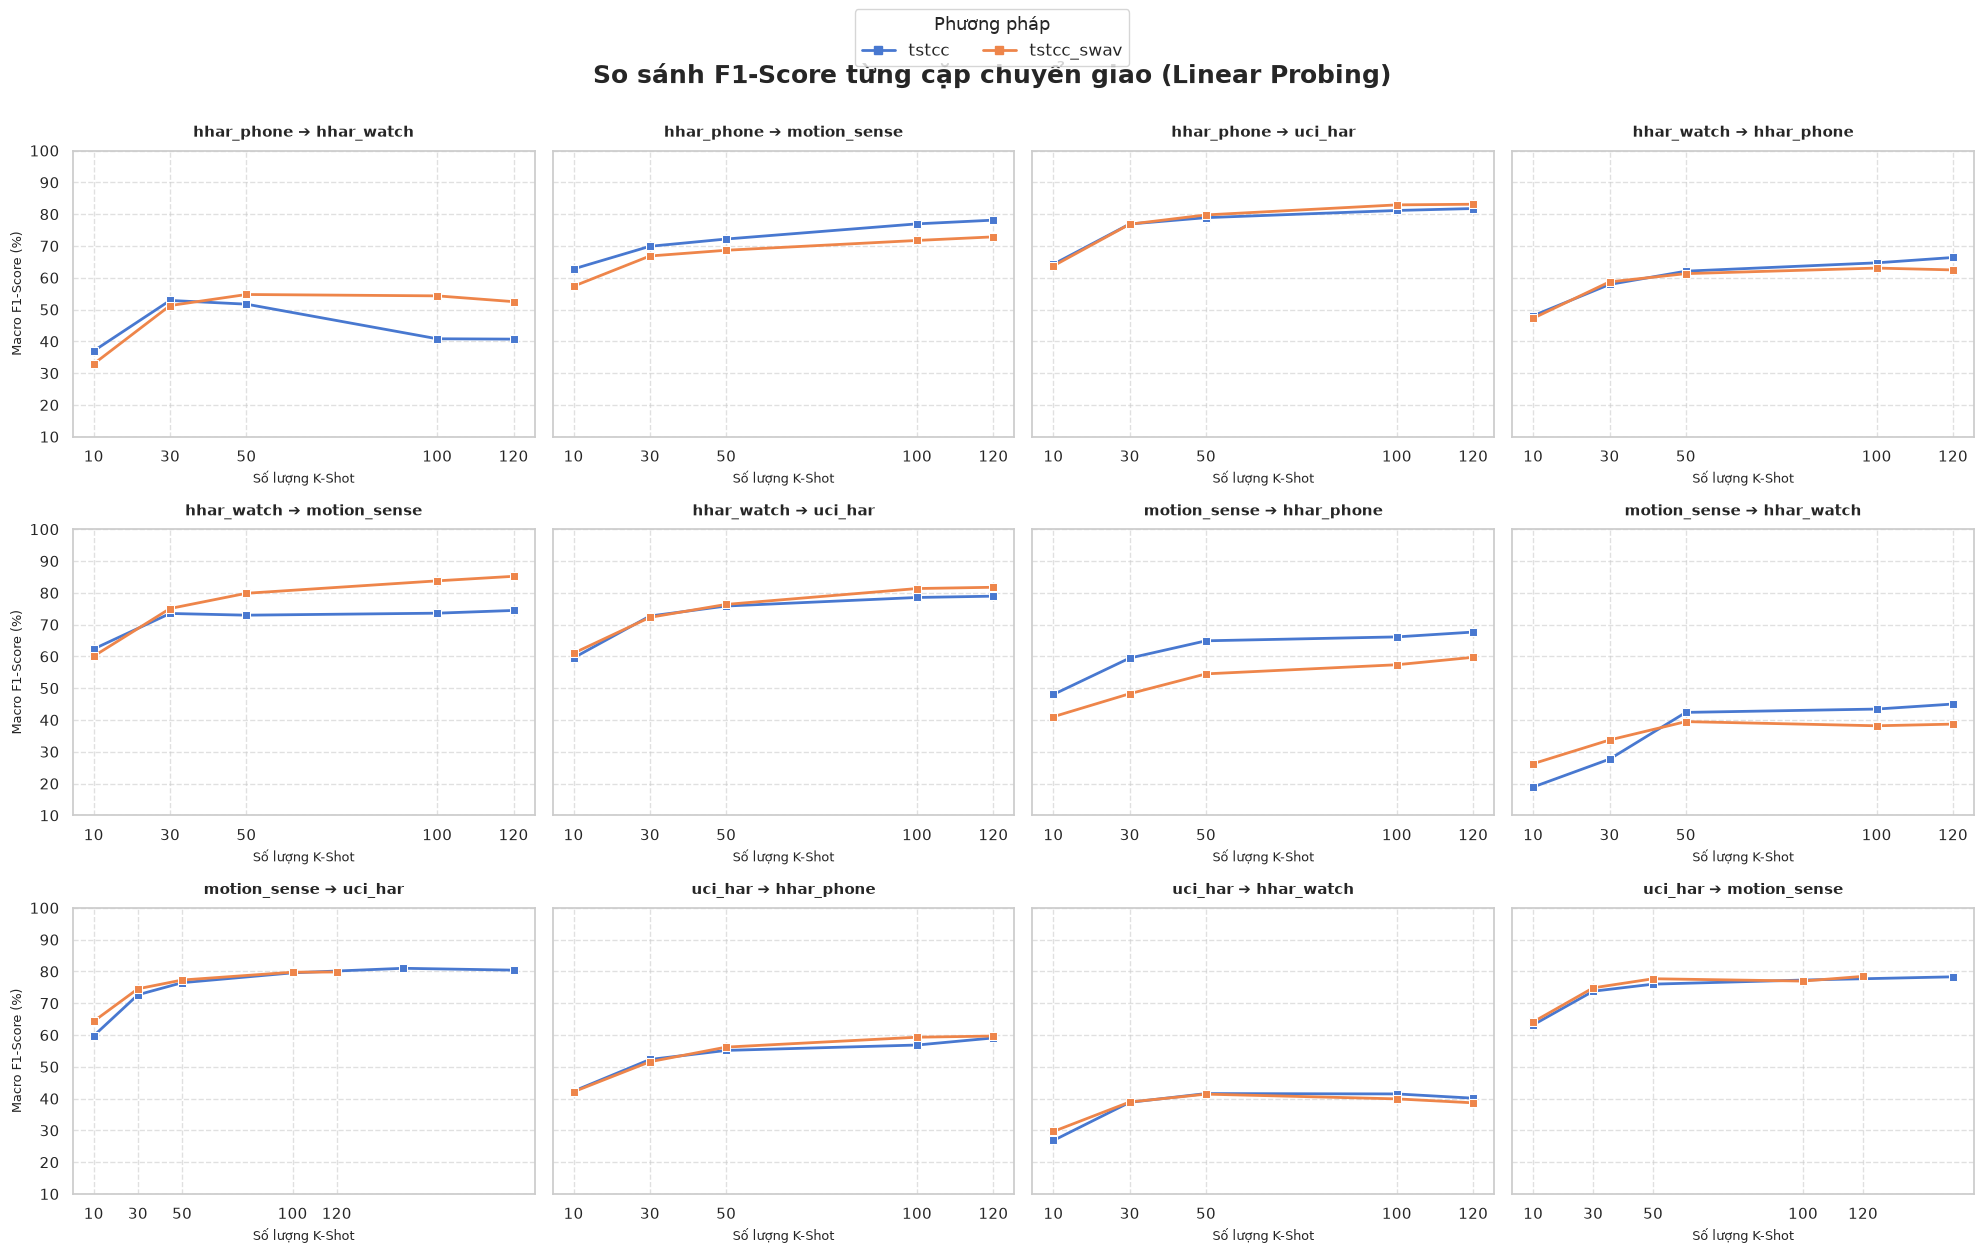

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Lấy dữ liệu Linear Probing
df_linear = df_compare[df_compare['Protocol'] == 'linear_probing'].copy()

# Lấy danh sách 12 cặp và sắp xếp
unique_pairs = sorted(df_linear['Pair'].unique())

# Tạo lưới biểu đồ
fig, axes = plt.subplots(3, 4, figsize=(20, 12), sharey=True)
axes = axes.flatten()

for i, pair in enumerate(unique_pairs):
    ax = axes[i]
    df_pair = df_linear[df_pair['Pair'] == pair] if False else df_linear[df_linear['Pair'] == pair]

    sns.lineplot(
        data=df_pair, x='Shots_Int', y='F1_Mean', hue='Method',
        marker='s', linewidth=2, markersize=6, ax=ax, legend=False
    )

    ax.set_title(f'{pair}', fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel('Số lượng K-Shot', fontsize=9)
    ax.set_ylabel('Macro F1-Score (%)', fontsize=9)
    ax.set_xticks([10, 30, 50, 100, 120])
    ax.set_ylim(10, 100)
    ax.grid(True, linestyle='--', alpha=0.6)

# Tạo Legend chung
custom_lines = [
    Line2D([0], [0], color=sns.color_palette("muted")[0], lw=2, marker='s'),
    Line2D([0], [0], color=sns.color_palette("muted")[1], lw=2, marker='s')
]

fig.legend(
    custom_lines,
    ['tstcc', 'tstcc_swav'],
    title='Phương pháp',
    loc='upper center',
    bbox_to_anchor=(0.5, 1.05),
    ncol=2,
    fontsize=12,
    title_fontsize=13
)

plt.suptitle('So sánh F1-Score từng cặp chuyển giao (Linear Probing)', fontsize=18, fontweight='bold', y=1.0)

plt.tight_layout()
plt.show()